In [ ]:
from google.colab import drive
from pathlib import Path
from PIL import Image

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil
import shutil, json, zipfile
from pathlib import Path

## Dataset

In [ ]:
SRC = Path('/content/drive/MyDrive/Colab Notebooks/dataset/nutrient-deficient')
CLASSES = ['boron', 'iron', 'manganese', 'healthy']
EXTS = {'.jpg', '.jpeg', '.png'}

In [ ]:
#kumpulkan path per kelas
files = {
    c: sorted(p for p in (SRC / c).iterdir() if p.suffix.lower() in EXTS)
    for c in CLASSES
}

#jumlah per kelas
for c in CLASSES:
    print(f'{c}: {len(files[c])}')
print('total:', sum(len(v) for v in files.values()))

#3 nama file pertama per kelas
for c in CLASSES:
    print(c, [p.name for p in files[c][:3]])

#size dan mode satu gambar per kelas
for c in CLASSES:
    im = Image.open(files[c][0])
    print(c, im.size, im.mode)

boron: 800
iron: 860
manganese: 840
healthy: 950
total: 3450
boron ['b1.jpg', 'b10.jpg', 'b100.jpg']
iron ['fe1.jpg', 'fe10.jpg', 'fe100.jpg']
manganese ['mn1.jpg', 'mn10.jpg', 'mn100.jpg']
healthy ['h_1.jpg', 'h_10.jpg', 'h_100.jpg']
boron (255, 255) RGB
iron (255, 255) RGB
manganese (255, 255) RGB
healthy (255, 255) RGB


In [ ]:
for c in CLASSES:
    shutil.copytree(SRC / c, Path('/content/data_raw') / c)
SRC = Path('/content/data_raw')

In [ ]:
#cek file rusak + ringkas mode/size seluruh dataset
from collections import Counter
bad, modes, sizes = [], Counter(), Counter()
for c in CLASSES:
    for p in files[c]:
        try:
            with Image.open(p) as im:
                im.verify()
            with Image.open(p) as im:
                modes[im.mode] += 1
                sizes[im.size] += 1
        except Exception as e:
            bad.append((p.name, str(e)))
print('rusak:', len(bad), bad[:5])
print('mode:', dict(modes))
print('size:', dict(sizes))

rusak: 0 []
mode: {'RGB': 3450}
size: {(255, 255): 3450}


## split

In [ ]:
import random

rng = random.Random(42)
TEST_N = {'boron': 81, 'iron': 72, 'manganese': 83, 'healthy': 69}  # 305
VAL_FRAC = 0.20

split = {}
for c in CLASSES:
    fl = files[c][:]
    rng.shuffle(fl)
    test = fl[:TEST_N[c]]
    rest = fl[TEST_N[c]:]
    n_val = round(VAL_FRAC * len(rest))
    split[c] = dict(val=rest[:n_val], train=rest[n_val:], test=test)

# tabel
print(f"{'class':<10}{'total':>6}{'test':>6}{'train':>7}{'val':>5}")
for c in CLASSES:
    s = split[c]
    print(f"{c:<10}{len(files[c]):>6}{len(s['test']):>6}{len(s['train']):>7}{len(s['val']):>5}")

# cek: tidak ada file di dua split
for c in CLASSES:
    s = split[c]
    a, b, t = set(s['train']), set(s['val']), set(s['test'])
    assert not (a & b) and not (a & t) and not (b & t), c
    assert len(a) + len(b) + len(t) == len(files[c]), c
print('ok: tidak ada overlap, total cocok')

class      total  test  train  val
boron        797    81    573  143
iron         860    77    626  157
manganese    840    95    596  149
healthy      950    69    705  176
ok: tidak ada overlap, total cocok


## Augmentasi

In [ ]:
import numpy as np
from PIL import Image
from pathlib import Path
import shutil

try:
    from tensorflow.keras.preprocessing.image import ImageDataGenerator
except Exception:
    from keras.src.legacy.preprocessing.image import ImageDataGenerator

OUT = Path('/content/data')
if OUT.exists():
    shutil.rmtree(OUT)

IMG_SIZE = 299
TARGET = {'train': 800, 'val': 200}
PREFIX = {'boron': 'b', 'iron': 'i', 'manganese': 'm', 'healthy': 'h'}

# Table 4 (rescale akan diterapkan di loader training)
gen = ImageDataGenerator(
    brightness_range=[0.8, 0.8],
    zoom_range=0.2,
    rotation_range=90,
    horizontal_flip=True,
)

def load(p):
    return Image.open(p).convert('RGB').resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)

np.random.seed(42)
rng = random.Random(42)

for c in CLASSES:
    for sp in ('train', 'val', 'test'):
        d = OUT / sp / c
        d.mkdir(parents=True, exist_ok=True)
        fl = split[c][sp]

        # salin asli (resize 299)
        for p in fl:
            load(p).save(d / f'{p.stem}.png')

        if sp == 'test':
            continue

        # augmentasi sampai target
        n_aug = TARGET[sp] - len(fl)
        pool = fl[:]
        rng.shuffle(pool)
        for k in range(n_aug):
            p = pool[k % len(pool)]
            x = np.asarray(load(p), dtype=np.float32)
            x = gen.random_transform(x)
            name = f'{PREFIX[c]}_aug_{k:04d}_{p.stem}.png'
            Image.fromarray(np.clip(x, 0, 255).astype(np.uint8)).save(d / name)

# cek jumlah
for sp in ('train', 'val', 'test'):
    print(sp, {c: len(list((OUT / sp / c).glob('*.png'))) for c in CLASSES})

train {'boron': 800, 'iron': 800, 'manganese': 800, 'healthy': 800}
val {'boron': 143, 'iron': 157, 'manganese': 149, 'healthy': 176}
test {'boron': 81, 'iron': 77, 'manganese': 95, 'healthy': 69}


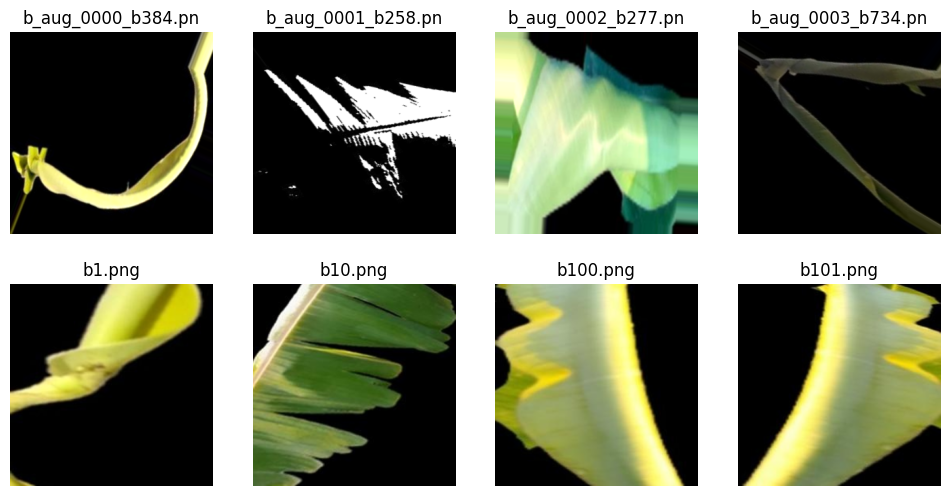

In [ ]:
#visualisasi
import matplotlib.pyplot as plt
d = OUT / 'train' / 'boron'
ims = sorted(d.glob('b_aug_*.png'))[:4] + sorted(p for p in d.glob('*.png') if '_aug_' not in p.name)[:4]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, p in zip(ax.ravel(), ims):
    a.imshow(Image.open(p)); a.set_title(p.name[:18]); a.axis('off')
plt.show()

In [ ]:
#simpan
DRIVE = Path('/content/drive/MyDrive/Colab Notebooks/dataset')

manifest = {c: {sp: [p.name for p in split[c][sp]] for sp in ('train', 'val', 'test')} for c in CLASSES}
with open('/content/split_manifest.json', 'w') as f:
    json.dump(manifest, f)

shutil.make_archive('/content/nd_clean', 'zip', '/content/data')
shutil.copy('/content/nd_clean.zip', DRIVE / 'nd_clean.zip')
shutil.copy('/content/split_manifest.json', DRIVE / 'split_manifest_clean.json')

z = zipfile.ZipFile(DRIVE / 'nd_clean.zip')
print('file di zip:', sum(n.endswith('.png') for n in z.namelist()))   # 4133
print('ukuran MB  :', round((DRIVE / 'nd_clean.zip').stat().st_size / 1e6))

file di zip: 4147
ukuran MB  : 295


## Restore

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, pickle, time, zipfile, shutil
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.metrics import precision_recall_fscore_support as prfs, confusion_matrix
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.inception_v3 import preprocess_input as pp_inc
from tensorflow.keras.applications.densenet import preprocess_input as pp_dense

# restore data
Z = '/content/drive/MyDrive/Colab Notebooks/dataset/nd_prepared.zip'
if not Path('/content/data/train').exists():
    shutil.copy(Z, '/content/nd_prepared.zip')
    zipfile.ZipFile('/content/nd_prepared.zip').extractall('/content/data')

DATA  = '/content/data'
NAMES = ['boron', 'healthy', 'iron', 'manganese']
FEAT  = Path('/content/drive/MyDrive/Colab Notebooks/nutrient-deficient/tlmvit')
FEAT.mkdir(parents=True, exist_ok=True)
RES = pickle.load(open(FEAT / 'RES_new.pkl', 'rb'))
print(list(RES.keys()))

def make_loader(split, pp, batch=32):
    idg = ImageDataGenerator(preprocessing_function=pp)
    return idg.flow_from_directory(
        f'{DATA}/{split}', target_size=(299, 299), batch_size=batch,
        class_mode='sparse', color_mode='rgb', shuffle=False)

# cek
print('GPU:', tf.config.list_physical_devices('GPU'))
for tag, pp in [('inc', pp_inc), ('dense', pp_dense)]:
    print('==', tag)
    ld = {s: make_loader(s, pp) for s in ('train', 'val', 'test')}
    print({s: l.samples for s, l in ld.items()})          # harapan 3200 800 305
    x, y = next(ld['train'])
    print(x.shape, y[:8], round(float(x.min()), 2), round(float(x.max()), 2))
print(ld['train'].class_indices)                          # harapan boron0 healthy1 iron2 manganese3

Mounted at /content/drive
[]
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
== inc
Found 3200 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 305 images belonging to 4 classes.
{'train': 3200, 'val': 800, 'test': 305}
(32, 299, 299, 3) [0. 0. 0. 0. 0. 0. 0. 0.] -1.0 1.0
== dense
Found 3200 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 305 images belonging to 4 classes.
{'train': 3200, 'val': 800, 'test': 305}
(32, 299, 299, 3) [0. 0. 0. 0. 0. 0. 0. 0.] -2.12 2.64
{'boron': 0, 'healthy': 1, 'iron': 2, 'manganese': 3}


In [ ]:
for p in FEAT.glob('*_prob_*.npy'): p.unlink()
pickle.dump({}, open(FEAT / 'RES_new.pkl', 'wb'))
RES = {}
print(list(FEAT.glob('*_prob_*.npy')), RES)

[] {}


## Ekstraksi

In [ ]:
# InceptionV3
import time
from tensorflow.keras.applications import InceptionV3, DenseNet169

def extract(base, pp, split):
    ld = make_loader(split, pp)
    out = np.zeros((ld.samples, *base.output_shape[1:]), dtype='float32')
    for i in range(len(ld)):
        xb, _ = ld[i]
        s = i * ld.batch_size
        out[s:s + len(xb)] = base.predict(xb, verbose=0)
    return out, ld.classes.astype('int32')

def run_extract(tag, base, pp):
    print(tag, 'out shape:', base.output_shape)
    for sp in ('train', 'val', 'test'):
        t = time.time()
        f, y = extract(base, pp, sp)
        np.save(FEAT / f'{tag}_{sp}_feat.npy', f)
        np.save(FEAT / f'{tag}_{sp}_lab.npy', y)
        print(f'  {sp}: {f.shape} | label {np.bincount(y)} | {time.time()-t:.0f}s')
        del f

base_inc = InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_inc.trainable = False
run_extract('inc', base_inc, pp_inc)

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
inc out shape: (None, 8, 8, 2048)
Found 3200 images belonging to 4 classes.
  train: (3200, 8, 8, 2048) | label [800 800 800 800] | 119s
Found 800 images belonging to 4 classes.
  val: (800, 8, 8, 2048) | label [200 200 200 200] | 47s
Found 305 images belonging to 4 classes.
  test: (305, 8, 8, 2048) | label [81 69 72 83] | 22s


In [ ]:
# DenseNet169
import gc
del base_inc; tf.keras.backend.clear_session(); gc.collect()

base_dense = DenseNet169(weights='imagenet', include_top=False, input_shape=(299, 299, 3))
base_dense.trainable = False
run_extract('dense', base_dense, pp_dense)

51877672/51877672 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
dense out shape: (None, 9, 9, 1664)
Found 3200 images belonging to 4 classes.
  train: (3200, 9, 9, 1664) | label [800 800 800 800] | 151s
Found 800 images belonging to 4 classes.
  val: (800, 9, 9, 1664) | label [200 200 200 200] | 37s
Found 305 images belonging to 4 classes.
  test: (305, 9, 9, 1664) | label [81 69 72 83] | 52s


### IncepV3 + IncepV3 Mutated

In [ ]:
import re
import time, gc
from tensorflow.keras import layers, models
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, Callback

class EpochTimer(Callback):
    def on_train_begin(self, logs=None): self.t = []
    def on_epoch_begin(self, epoch, logs=None): self._s = time.time()
    def on_epoch_end(self, epoch, logs=None): self.t.append(time.time() - self._s)

def report(name, hs=None, cm=None):
    if re.search(r' s\d+$', name): return          # seed 1,2: tanpa plot
    if hs is not None:
        h = hs.history; pickle.dump(h, open(FEAT / f'hist_{name}.pkl', 'wb'))
        fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
        for a, k in zip(ax, ['accuracy', 'loss']):
            a.plot(h[k], label='train'); a.plot(h['val_'+k], label='val')
            a.axvline(int(np.argmin(h['val_loss'])), ls='--', c='gray')
            a.set_title(f'{name} - {k}'); a.set_xlabel('epoch'); a.legend()
        plt.tight_layout(); plt.show()
    if cm is not None:
        plt.figure(figsize=(4, 3.5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=NAMES, yticklabels=NAMES)
        plt.title(f'{name} - test'); plt.xlabel('pred'); plt.ylabel('true'); plt.show()

def load_feat(tag):
    f = {s: np.load(FEAT / f'{tag}_{s}_feat.npy') for s in ('train', 'val', 'test')}
    y = {s: np.load(FEAT / f'{tag}_{s}_lab.npy') for s in ('train', 'val', 'test')}
    return f, y

def evaluate_prob(name, pv, pt, yv_true, yt_true, epochs=None, sec=None):
    yv, yt = pv.argmax(1), pt.argmax(1)
    Pm, Rm, Fm, _ = prfs(yv_true, yv, average='macro', zero_division=0)
    p, r, f, s = prfs(yt_true, yt, zero_division=0)
    cm = confusion_matrix(yt_true, yt)
    ok, n = int((yt == yt_true).sum()), len(yt_true)
    RES[name] = dict(
        t14=dict(Epochs=epochs, Sec_per_epoch=sec, Precision=Pm*100, Recall=Rm*100, F1=Fm*100, Accuracy=(yv == yv_true).mean()*100),
        t15={'True %': ok/n*100, 'True n': ok, 'False %': (n-ok)/n*100, 'False n': n-ok},
        t17=dict(zip(NAMES, cm.diagonal() / cm.sum(1) * 100)))
    report(name, cm=cm)
    return cm

def show(keys):
    for k, t in [('t14', 'Overall (val)'), ('t15', 'Prediction 305 test'), ('t17', 'Acc per kelas (test)')]:
        print('\n' + t)
        display(pd.DataFrame({n: RES[n][k] for n in keys}).T.round(2))

RES = pickle.load(open(FEAT / 'RES_new.pkl', 'rb'))
print(list(RES.keys()))

[]


In [ ]:
from tensorflow.keras import regularizers

def run_base(tag, name, hidden=(), seed=42, lr=1e-3, bs=32, l2=0.0, drop=0.5):
    f, y = load_feat(tag)
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    i = layers.Input(f['train'].shape[1:])
    x = layers.GlobalAveragePooling2D()(i)
    for h in hidden:
        x = layers.Dense(h, activation='relu',
                         kernel_regularizer=regularizers.l2(l2) if l2 else None)(x)
        x = layers.Dropout(drop)(x)          # dropout tiap hidden
    m = models.Model(i, layers.Dense(4, activation='softmax')(layers.Dropout(drop)(x)), name=name.replace(' ', '_'))
    m.compile(Adam(lr), 'sparse_categorical_crossentropy', metrics=['accuracy'])

    tm = EpochTimer()
    hs = m.fit(f['train'], y['train'], validation_data=(f['val'], y['val']),
               batch_size=bs, epochs=35, verbose=0,
               callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True), tm])

    pv, pt = m.predict(f['val'], verbose=0), m.predict(f['test'], verbose=0)
    cm = evaluate_prob(name, pv, pt, y['val'], y['test'], epochs=len(hs.history['loss']), sec=float(np.mean(tm.t)))
    report(name, hs)
    np.save(FEAT / f'{name}_prob_val.npy', pv); np.save(FEAT / f'{name}_prob_test.npy', pt)
    pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
    return cm

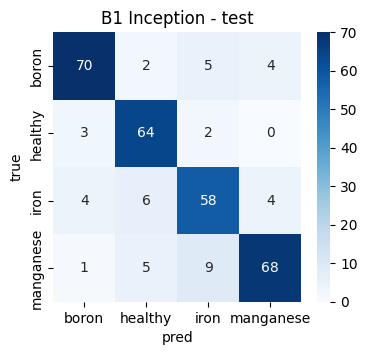

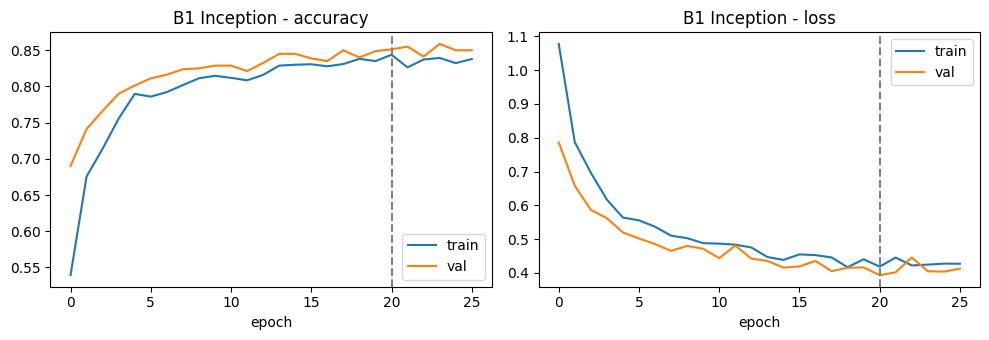

In [ ]:
cm_b1i = run_base('inc', 'B1 Inception')

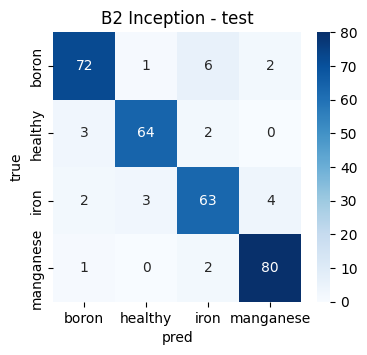

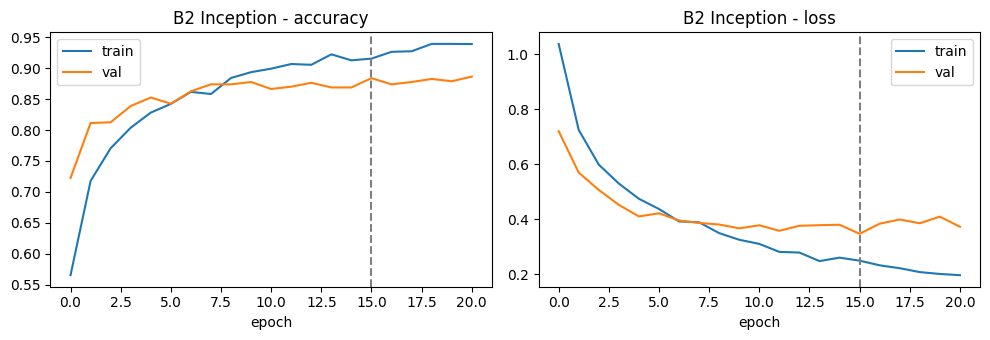

In [ ]:
cm_b2i = run_base('inc', 'B2 Inception', hidden=(128,), lr=1e-3, l2=1e-4, drop=0.3)

In [ ]:
show(['B1 Inception', 'B2 Inception'])


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 Inception,26.0,1.99,85.33,85.12,85.20,85.12
B2 Inception,21.0,1.99,88.65,88.38,88.44,88.38



Prediction 305 test


,True %,True n,False %,False n
B1 Inception,85.25,260.0,14.75,45.0
B2 Inception,91.48,279.0,8.52,26.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 Inception,86.42,92.75,80.56,81.93
B2 Inception,88.89,92.75,87.50,96.39


### dense169 + dense169 Mutated

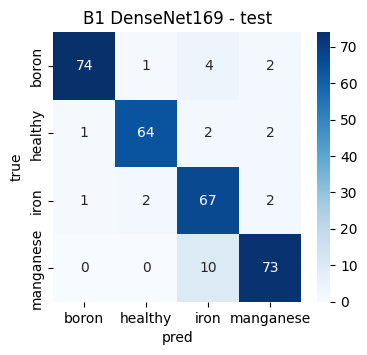

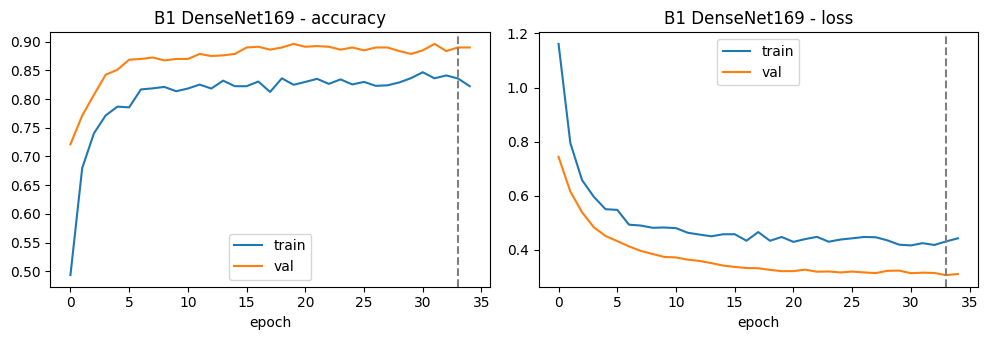

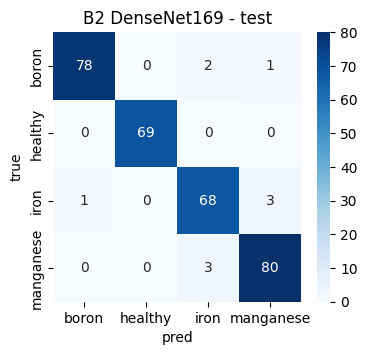

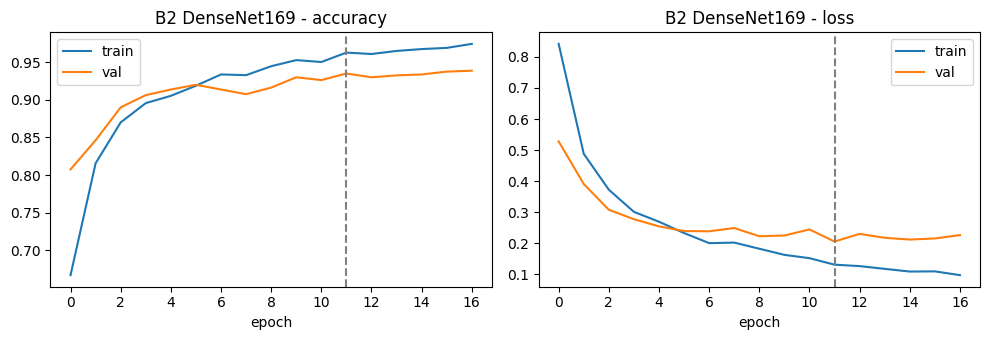


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 DenseNet169,35.0,1.93,89.10,89.0,89.02,89.0
B2 DenseNet169,17.0,1.80,93.53,93.5,93.49,93.5



Prediction 305 test


,True %,True n,False %,False n
B1 DenseNet169,91.15,278.0,8.85,27.0
B2 DenseNet169,96.72,295.0,3.28,10.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 DenseNet169,91.36,92.75,93.06,87.95
B2 DenseNet169,96.30,100.00,94.44,96.39


In [ ]:
cm_b1d = run_base('dense', 'B1 DenseNet169')
cm_b2d = run_base('dense', 'B2 DenseNet169', hidden=(128,), lr=1e-3, l2=1e-4, drop=0.3)
show(['B1 DenseNet169', 'B2 DenseNet169'])

## Ensemble (Average)

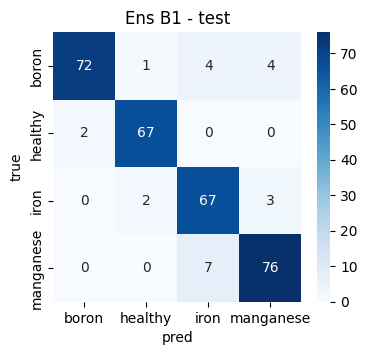

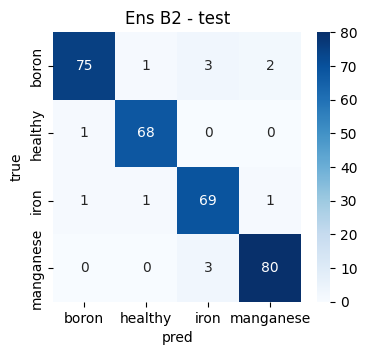


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 Inception,26.0,1.99,85.33,85.12,85.20,85.12
B1 DenseNet169,35.0,1.93,89.10,89.00,89.02,89.00
Ens B1,NaN,NaN,90.79,90.62,90.67,90.62
B2 Inception,21.0,1.99,88.65,88.38,88.44,88.38
B2 DenseNet169,17.0,1.80,93.53,93.50,93.49,93.50
Ens B2,NaN,NaN,93.68,93.62,93.64,93.62



Prediction 305 test


,True %,True n,False %,False n
B1 Inception,85.25,260.0,14.75,45.0
B1 DenseNet169,91.15,278.0,8.85,27.0
Ens B1,92.46,282.0,7.54,23.0
B2 Inception,91.48,279.0,8.52,26.0
B2 DenseNet169,96.72,295.0,3.28,10.0
Ens B2,95.74,292.0,4.26,13.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 Inception,86.42,92.75,80.56,81.93
B1 DenseNet169,91.36,92.75,93.06,87.95
Ens B1,88.89,97.10,93.06,91.57
B2 Inception,88.89,92.75,87.50,96.39
B2 DenseNet169,96.30,100.00,94.44,96.39
Ens B2,92.59,98.55,95.83,96.39


In [ ]:
yv, yt = np.load(FEAT / 'inc_val_lab.npy'), np.load(FEAT / 'inc_test_lab.npy')
assert np.array_equal(yt, np.load(FEAT / 'dense_test_lab.npy'))
assert np.array_equal(yv, np.load(FEAT / 'dense_val_lab.npy'))

def ens(name, a, b):
    P = {s: [np.load(FEAT / f'{n}_prob_{s}.npy') for n in (a, b)] for s in ('val', 'test')}
    for s, n_ in (('val', len(yv)), ('test', len(yt))):
        assert all(p.shape == (n_, 4) for p in P[s]), (name, s)
    return evaluate_prob(name, sum(P['val'])/2, sum(P['test'])/2, yv, yt)

cm_e1 = ens('Ens B1', 'B1 Inception', 'B1 DenseNet169')
cm_e2 = ens('Ens B2', 'B2 Inception', 'B2 DenseNet169')
pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
show(['B1 Inception', 'B1 DenseNet169', 'Ens B1', 'B2 Inception', 'B2 DenseNet169', 'Ens B2'])

In [ ]:
assert np.array_equal(yv, np.load(FEAT / 'dense_val_lab.npy'))
assert np.array_equal(yt, np.load(FEAT / 'dense_test_lab.npy'))

for n in ['B1 Inception','B1 DenseNet169','B2 Inception','B2 DenseNet169']:
    for s, y in (('val', yv), ('test', yt)):
        p = np.load(FEAT / f'{n}_prob_{s}.npy')
        assert p.shape == (len(y), 4) and np.allclose(p.sum(1), 1, atol=1e-3), (n, s)
    # prob tersimpan == RES
    ok = int((np.load(FEAT / f'{n}_prob_test.npy').argmax(1) == yt).sum())
    assert ok == RES[n]['t15']['True n'], (n, ok, RES[n]['t15']['True n'])

for e, a, b in [('Ens B1','B1 Inception','B1 DenseNet169'), ('Ens B2','B2 Inception','B2 DenseNet169')]:
    pe = (np.load(FEAT / f'{a}_prob_test.npy') + np.load(FEAT / f'{b}_prob_test.npy')) / 2
    assert int((pe.argmax(1) == yt).sum()) == RES[e]['t15']['True n'], e

import os
for n in ['B1 Inception','B1 DenseNet169','B2 Inception','B2 DenseNet169']:   # tidak basi
    assert os.path.getmtime(FEAT / f'{n}_prob_test.npy') > os.path.getmtime(FEAT / 'inc_test_feat.npy'), n
print('valid')

valid


## TLM-ViT 1

parameter: Adam 1e-3, batch 32, max 35 epoch

### Densenet169

In [ ]:
import gc
from tensorflow.keras import regularizers

def run_base(tag, name, hidden=(), seed=42, lr=1e-3, bs=32, l2=0.0, drop=0.5,
             build=None, monitor='val_loss'):
    f, y = load_feat(tag)
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    if build:
        m = build(f['train'].shape[1:])
    else:
        i = layers.Input(f['train'].shape[1:])
        x = layers.GlobalAveragePooling2D()(i)
        for h in hidden:
            x = layers.Dense(h, activation='relu',
                             kernel_regularizer=regularizers.l2(l2) if l2 else None)(x)
            x = layers.Dropout(drop)(x)
        m = models.Model(i, layers.Dense(4, activation='softmax')(layers.Dropout(drop)(x)),
                         name=name.replace(' ', '_'))
    m.compile(Adam(lr), 'sparse_categorical_crossentropy', metrics=['accuracy'])

    tm = EpochTimer()
    hs = m.fit(f['train'], y['train'], validation_data=(f['val'], y['val']),
               batch_size=bs, epochs=35, verbose=0,
               callbacks=[EarlyStopping(monitor=monitor, patience=5, restore_best_weights=True), tm])

    pv, pt = m.predict(f['val'], verbose=0), m.predict(f['test'], verbose=0)
    cm = evaluate_prob(name, pv, pt, y['val'], y['test'], epochs=len(hs.history['loss']), sec=float(np.mean(tm.t)))
    report(name, hs)
    np.save(FEAT / f'{name}_prob_val.npy', pv); np.save(FEAT / f'{name}_prob_test.npy', pt)
    pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
    del f, y, m; gc.collect()
    return cm

In [ ]:
class PatchEncoder(layers.Layer):
    def __init__(self, n, dim, **kw):
        super().__init__(**kw); self.n, self.dim = n, dim
        self.proj = layers.Dense(dim); self.pos = layers.Embedding(n, dim)
    def call(self, x):
        return self.proj(x) + self.pos(tf.range(self.n))

def build_tlmvit(shape, patch, dim=64, heads=4, depth=2, drop=0.3, head=(512, 256)):
    H, W, C = shape; n = (H // patch) * (W // patch)
    i = layers.Input(shape)
    x = PatchEncoder(n, dim)(layers.Dropout(drop)(PatchExtractor(patch)(i)))
    for _ in range(depth):
        h = layers.LayerNormalization(epsilon=1e-6)(x)
        h = layers.MultiHeadAttention(heads, dim // heads, dropout=drop)(h, h)
        x = layers.Add()([x, h])
        h = layers.LayerNormalization(epsilon=1e-6)(x)
        h = layers.Dropout(drop)(layers.Dense(dim * 2, activation='gelu')(h))
        h = layers.Dropout(drop)(layers.Dense(dim)(h))
        x = layers.Add()([x, h])
    x = layers.Flatten()(layers.LayerNormalization(epsilon=1e-6)(x))
    for u in head:
        x = layers.Dropout(drop)(layers.Dense(u, activation='relu')(x))
    return models.Model(i, layers.Dense(4, activation='softmax')(x))

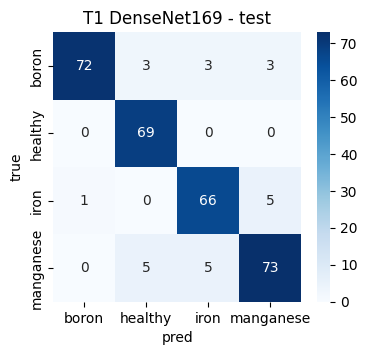

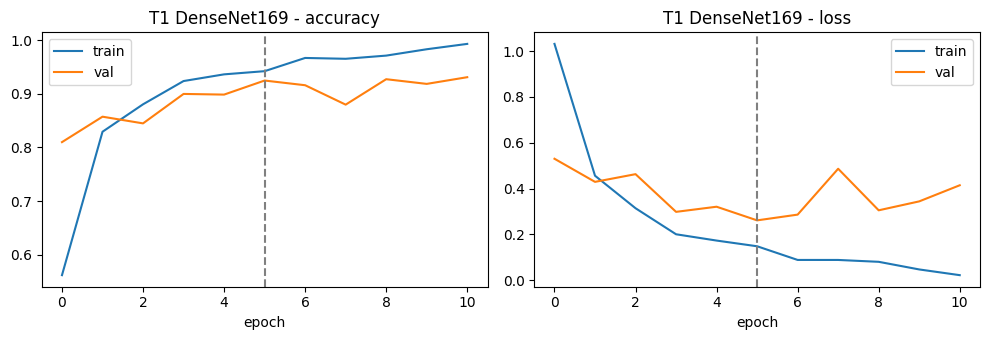


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 DenseNet169,35.0,1.93,89.10,89.0,89.02,89.0
B2 DenseNet169,17.0,1.80,93.53,93.5,93.49,93.5
T1 DenseNet169,11.0,4.38,92.61,92.5,92.49,92.5



Prediction 305 test


,True %,True n,False %,False n
B1 DenseNet169,91.15,278.0,8.85,27.0
B2 DenseNet169,96.72,295.0,3.28,10.0
T1 DenseNet169,91.80,280.0,8.20,25.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 DenseNet169,91.36,92.75,93.06,87.95
B2 DenseNet169,96.30,100.00,94.44,96.39
T1 DenseNet169,88.89,100.00,91.67,87.95


In [ ]:
cm_t1d = run_base('dense', 'T1 DenseNet169', lr=3e-4, build=lambda s: build_tlmvit(s, patch=2))
show(['B1 DenseNet169', 'B2 DenseNet169', 'T1 DenseNet169'])

### InceptionV3

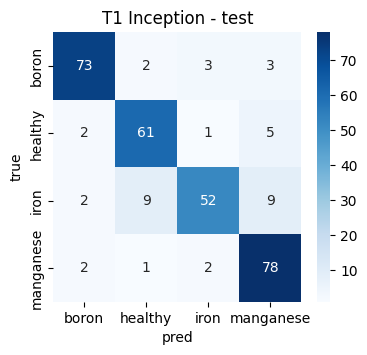

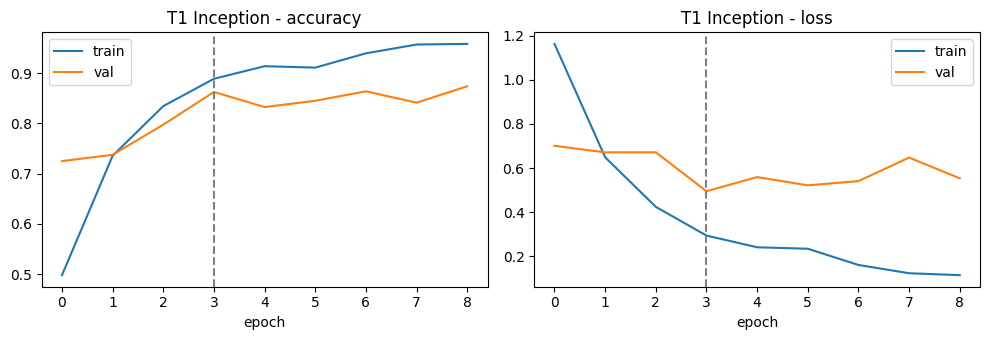


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 Inception,26.0,1.99,85.33,85.12,85.20,85.12
B2 Inception,21.0,1.99,88.65,88.38,88.44,88.38
T1 Inception,9.0,5.68,87.38,86.25,86.26,86.25



Prediction 305 test


,True %,True n,False %,False n
B1 Inception,85.25,260.0,14.75,45.0
B2 Inception,91.48,279.0,8.52,26.0
T1 Inception,86.56,264.0,13.44,41.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 Inception,86.42,92.75,80.56,81.93
B2 Inception,88.89,92.75,87.50,96.39
T1 Inception,90.12,88.41,72.22,93.98


In [ ]:
cm_t1i = run_base('inc',   'T1 Inception',   lr=3e-4, build=lambda s: build_tlmvit(s, patch=2))
show(['B1 Inception', 'B2 Inception', 'T1 Inception'])

## TLM-ViT 2

In [ ]:
import types
from tensorflow.keras.applications import DenseNet169, InceptionV3

def run_t2(name, make_base, pp, unfreeze, seed=42, e1=20, e2=15):
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
    A = dict(rotation_range=20, width_shift_range=0.2, height_shift_range=0.2,
             shear_range=0.2, zoom_range=0.2, horizontal_flip=True, fill_mode='nearest')
    kw = dict(target_size=(299, 299), batch_size=16, class_mode='sparse')
    tr = ImageDataGenerator(preprocessing_function=pp, **A).flow_from_directory(f'{DATA}/train', shuffle=True, seed=seed, **kw)
    plain = ImageDataGenerator(preprocessing_function=pp)
    va = plain.flow_from_directory(f'{DATA}/val',  shuffle=False, **kw)
    te = plain.flow_from_directory(f'{DATA}/test', shuffle=False, **kw)

    base = make_base(); base.trainable = False
    inp = layers.Input((299, 299, 3))
    vit = build_tlmvit(base.output_shape[1:], patch=1, depth=2, drop=0.3)
    m = models.Model(inp, vit(base(inp, training=False)))
    cb = lambda: [EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                  tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)]

    tm = EpochTimer()
    m.compile(Adam(3e-4), 'sparse_categorical_crossentropy', metrics=['accuracy'])
    h1 = m.fit(tr, validation_data=va, epochs=e1, callbacks=cb() + [tm], verbose=2)     # tahap 1

    keep = unfreeze(base)
    base.trainable = True
    for l in base.layers:
        l.trainable = l.name in keep and not isinstance(l, layers.BatchNormalization)
    m.compile(Adam(1e-5), 'sparse_categorical_crossentropy', metrics=['accuracy'])
    h2 = m.fit(tr, validation_data=va, epochs=e2, callbacks=cb() + [tm], verbose=2)     # tahap 2

    pv, pt = m.predict(va, verbose=0), m.predict(te, verbose=0)
    hist = {k: h1.history[k] + h2.history[k] for k in h1.history if k in h2.history}
    cm = evaluate_prob(name, pv, pt, va.classes, te.classes,
                       epochs=len(hist['loss']), sec=float(np.mean(tm.t)))
    report(name, types.SimpleNamespace(history=hist))
    np.save(FEAT / f'{name}_prob_val.npy', pv); np.save(FEAT / f'{name}_prob_test.npy', pt)
    pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
    del m, base; gc.collect()
    return cm

dense_conv5 = lambda b: {l.name for l in b.layers if l.name.startswith('conv5')}
inc_last    = lambda b: {l.name for l in b.layers[[x.name for x in b.layers].index('mixed8') + 1:]}

Found 3200 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 305 images belonging to 4 classes.
Epoch 1/20
200/200 - 169s - 844ms/step - accuracy: 0.5113 - loss: 1.1614 - val_accuracy: 0.7713 - val_loss: 0.5823 - learning_rate: 3.0000e-04
Epoch 2/20
200/200 - 91s - 454ms/step - accuracy: 0.7709 - loss: 0.5850 - val_accuracy: 0.8288 - val_loss: 0.4147 - learning_rate: 3.0000e-04
Epoch 3/20
200/200 - 89s - 446ms/step - accuracy: 0.8294 - loss: 0.4573 - val_accuracy: 0.8263 - val_loss: 0.5531 - learning_rate: 3.0000e-04
Epoch 4/20
200/200 - 90s - 452ms/step - accuracy: 0.8634 - loss: 0.3787 - val_accuracy: 0.8800 - val_loss: 0.3105 - learning_rate: 3.0000e-04
Epoch 5/20
200/200 - 91s - 456ms/step - accuracy: 0.8662 - loss: 0.3550 - val_accuracy: 0.9125 - val_loss: 0.2799 - learning_rate: 3.0000e-04
Epoch 6/20
200/200 - 93s - 467ms/step - accuracy: 0.8856 - loss: 0.2975 - val_accuracy: 0.8712 - val_loss: 0.3753 - learning_rate: 3.0000e-04
Epoch 7/20
200/200 - 88

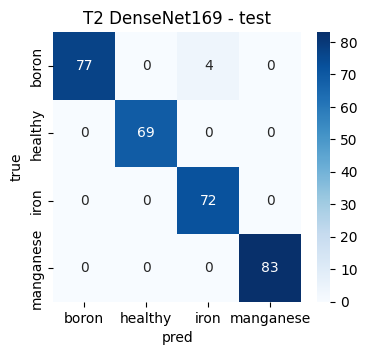

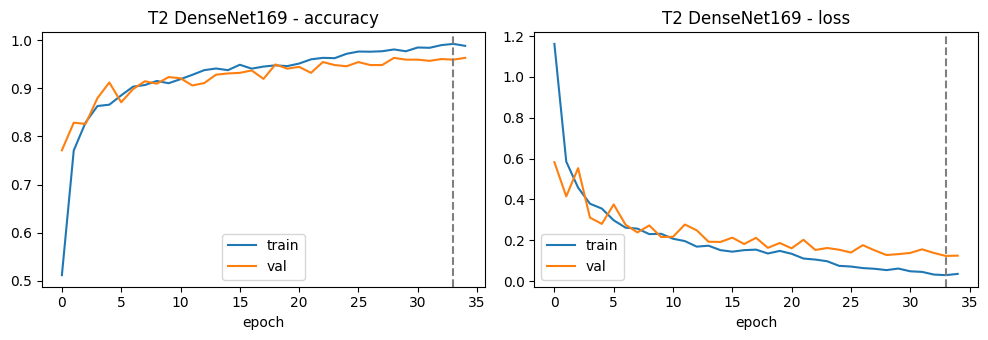

Found 3200 images belonging to 4 classes.
Found 800 images belonging to 4 classes.
Found 305 images belonging to 4 classes.
Epoch 1/20
200/200 - 124s - 619ms/step - accuracy: 0.4881 - loss: 1.2154 - val_accuracy: 0.6300 - val_loss: 0.9187 - learning_rate: 3.0000e-04
Epoch 2/20
200/200 - 82s - 409ms/step - accuracy: 0.6837 - loss: 0.7843 - val_accuracy: 0.7663 - val_loss: 0.5828 - learning_rate: 3.0000e-04
Epoch 3/20
200/200 - 83s - 415ms/step - accuracy: 0.7650 - loss: 0.5971 - val_accuracy: 0.7738 - val_loss: 0.5789 - learning_rate: 3.0000e-04
Epoch 4/20
200/200 - 85s - 423ms/step - accuracy: 0.7997 - loss: 0.5277 - val_accuracy: 0.7600 - val_loss: 0.7021 - learning_rate: 3.0000e-04
Epoch 5/20
200/200 - 85s - 427ms/step - accuracy: 0.8231 - loss: 0.4807 - val_accuracy: 0.8388 - val_loss: 0.3887 - learning_rate: 3.0000e-04
Epoch 6/20
200/200 - 82s - 412ms/step - accuracy: 0.8334 - loss: 0.4526 - val_accuracy: 0.8100 - val_loss: 0.5272 - learning_rate: 3.0000e-04
Epoch 7/20
200/200 - 82

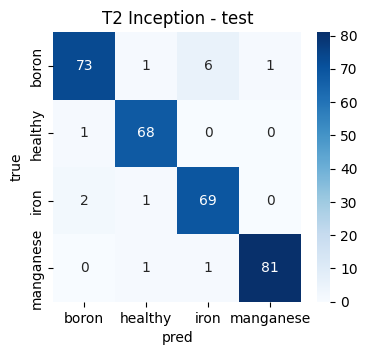

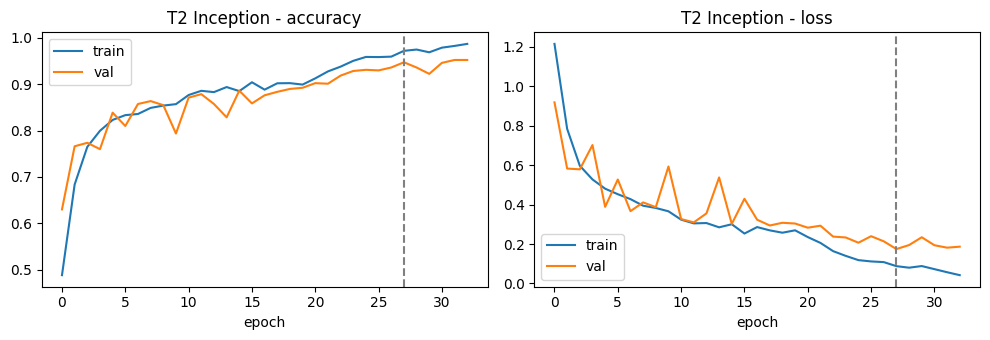


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 Inception,26.0,1.99,85.33,85.12,85.20,85.12
B2 Inception,21.0,1.99,88.65,88.38,88.44,88.38
T1 Inception,13.0,3.49,87.82,87.38,87.47,87.38
T2 Inception,33.0,87.62,94.75,94.75,94.75,94.75
B1 DenseNet169,35.0,1.93,89.10,89.00,89.02,89.00
B2 DenseNet169,17.0,1.80,93.53,93.50,93.49,93.50
T1 DenseNet169,17.0,3.74,92.86,92.75,92.73,92.75
T2 DenseNet169,35.0,95.19,95.99,96.00,95.99,96.00



Prediction 305 test


,True %,True n,False %,False n
B1 Inception,85.25,260.0,14.75,45.0
B2 Inception,91.48,279.0,8.52,26.0
T1 Inception,90.16,275.0,9.84,30.0
T2 Inception,95.41,291.0,4.59,14.0
B1 DenseNet169,91.15,278.0,8.85,27.0
B2 DenseNet169,96.72,295.0,3.28,10.0
T1 DenseNet169,93.44,285.0,6.56,20.0
T2 DenseNet169,98.69,301.0,1.31,4.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 Inception,86.42,92.75,80.56,81.93
B2 Inception,88.89,92.75,87.50,96.39
T1 Inception,92.59,88.41,80.56,97.59
T2 Inception,90.12,98.55,95.83,97.59
B1 DenseNet169,91.36,92.75,93.06,87.95
B2 DenseNet169,96.30,100.00,94.44,96.39
T1 DenseNet169,85.19,97.10,95.83,96.39
T2 DenseNet169,95.06,100.00,100.00,100.00


In [ ]:
cm_t2d = run_t2('T2 DenseNet169', lambda: DenseNet169(weights='imagenet', include_top=False, input_shape=(299, 299, 3)), pp_dense, dense_conv5)
cm_t2i = run_t2('T2 Inception',   lambda: InceptionV3(weights='imagenet', include_top=False, input_shape=(299, 299, 3)), pp_inc,   inc_last)
show(['B1 Inception', 'B2 Inception', 'T1 Inception', 'T2 Inception', 'B1 DenseNet169', 'B2 DenseNet169', 'T1 DenseNet169', 'T2 DenseNet169'])

In [ ]:
show(['B1 Inception', 'B2 Inception', 'T1 Inception', 'T2 Inception', 'B1 DenseNet169', 'B2 DenseNet169', 'T1 DenseNet169', 'T2 DenseNet169'])


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
B1 Inception,26.0,1.99,85.33,85.12,85.20,85.12
B2 Inception,21.0,1.99,88.65,88.38,88.44,88.38
T1 Inception,9.0,5.68,87.38,86.25,86.26,86.25
T2 Inception,33.0,87.62,94.75,94.75,94.75,94.75
B1 DenseNet169,35.0,1.93,89.10,89.00,89.02,89.00
B2 DenseNet169,17.0,1.80,93.53,93.50,93.49,93.50
T1 DenseNet169,11.0,4.38,92.61,92.50,92.49,92.50
T2 DenseNet169,35.0,95.19,95.99,96.00,95.99,96.00



Prediction 305 test


,True %,True n,False %,False n
B1 Inception,85.25,260.0,14.75,45.0
B2 Inception,91.48,279.0,8.52,26.0
T1 Inception,86.56,264.0,13.44,41.0
T2 Inception,95.41,291.0,4.59,14.0
B1 DenseNet169,91.15,278.0,8.85,27.0
B2 DenseNet169,96.72,295.0,3.28,10.0
T1 DenseNet169,91.80,280.0,8.20,25.0
T2 DenseNet169,98.69,301.0,1.31,4.0



Acc per kelas (test)


,boron,healthy,iron,manganese
B1 Inception,86.42,92.75,80.56,81.93
B2 Inception,88.89,92.75,87.50,96.39
T1 Inception,90.12,88.41,72.22,93.98
T2 Inception,90.12,98.55,95.83,97.59
B1 DenseNet169,91.36,92.75,93.06,87.95
B2 DenseNet169,96.30,100.00,94.44,96.39
T1 DenseNet169,88.89,100.00,91.67,87.95
T2 DenseNet169,95.06,100.00,100.00,100.00


## Ensemble (Average)

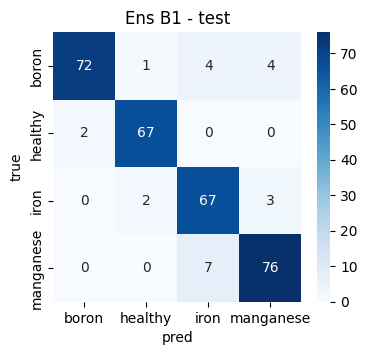

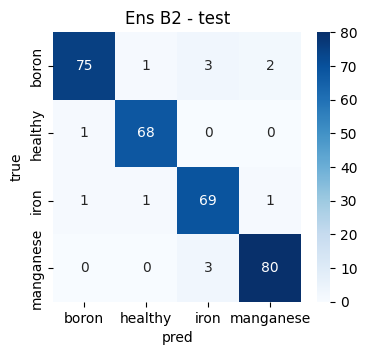

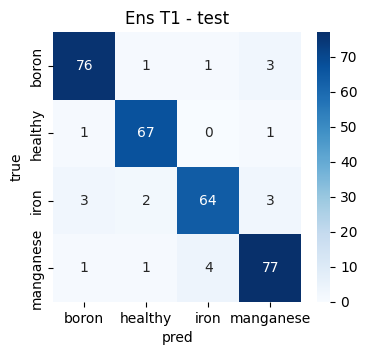

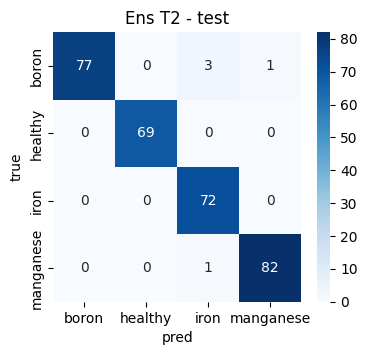


Overall (val)


,Epochs,Sec_per_epoch,Precision,Recall,F1,Accuracy
Ens B1,NaN,NaN,90.79,90.62,90.67,90.62
Ens B2,NaN,NaN,93.68,93.62,93.64,93.62
Ens T1,NaN,NaN,93.21,93.12,93.12,93.12
Ens T2,NaN,NaN,97.12,97.12,97.12,97.12



Prediction 305 test


,True %,True n,False %,False n
Ens B1,92.46,282.0,7.54,23.0
Ens B2,95.74,292.0,4.26,13.0
Ens T1,93.11,284.0,6.89,21.0
Ens T2,98.36,300.0,1.64,5.0



Acc per kelas (test)


,boron,healthy,iron,manganese
Ens B1,88.89,97.10,93.06,91.57
Ens B2,92.59,98.55,95.83,96.39
Ens T1,93.83,97.10,88.89,92.77
Ens T2,95.06,100.00,100.00,98.80


In [ ]:
yv, yt = np.load(FEAT / 'inc_val_lab.npy'), np.load(FEAT / 'inc_test_lab.npy')
def ens(name, a, b):
    P = {s: [np.load(FEAT / f'{n}_prob_{s}.npy') for n in (a, b)] for s in ('val', 'test')}
    return evaluate_prob(name, sum(P['val'])/2, sum(P['test'])/2, yv, yt)

ens('Ens B1', 'B1 Inception', 'B1 DenseNet169')
ens('Ens B2', 'B2 Inception', 'B2 DenseNet169')
ens('Ens T1', 'T1 Inception', 'T1 DenseNet169')
ens('Ens T2', 'T2 Inception', 'T2 DenseNet169')
pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
show(['Ens B1', 'Ens B2', 'Ens T1', 'Ens T2'])

In [ ]:
# multi seed
import gc, pickle
from pathlib import Path

vit = lambda s: build_tlmvit(s, patch=1, depth=2)
H = dict(hidden=(256, 256))

CFG = {
    'B1 Inception':    ('inc',   {}),
    'B1 DenseNet169':  ('dense', {}),
    'B2 Inception':    ('inc',   H),
    'B2 DenseNet169':  ('dense', H),
    'T1 Inception':    ('inc',   dict(build=vit)),
    'T1 DenseNet169':  ('dense', dict(build=vit)),
}

E = {
    'Ens B1':    ['B1 Inception', 'B1 DenseNet169'],
    'Ens B2':    ['B2 Inception', 'B2 DenseNet169'],
    'Ens T1':    ['T1 Inception', 'T1 DenseNet169'],
    'Ens B1+B2': ['B1 Inception', 'B1 DenseNet169', 'B2 Inception', 'B2 DenseNet169'],
    'Ens B2+T1': ['B2 Inception', 'B2 DenseNet169', 'T1 Inception', 'T1 DenseNet169'],
}

sfx = lambda n, sd: n if sd == 42 else f'{n} s{sd}'
SEEDS = (42, 1, 2)

# helper ensemble (n model)
def ensn(name, *models):
    """Average softmax dari beberapa model yang sudah punya _prob_*.npy"""
    yv = np.load(FEAT / 'inc_val_lab.npy')
    yt = np.load(FEAT / 'inc_test_lab.npy')
    pv = sum(np.load(FEAT / f'{m}_prob_val.npy')  for m in models) / len(models)
    pt = sum(np.load(FEAT / f'{m}_prob_test.npy') for m in models) / len(models)
    evaluate_prob(name, pv, pt, yv, yt)
    del pv, pt
    gc.collect()

# train hanya seed yang belum ada
def already_done(name):
    return (FEAT / f'{name}_prob_test.npy').exists()

for sd in SEEDS[1:]:
    for n, (tag, kw) in CFG.items():
        name = sfx(n, sd)
        if already_done(name):
            print(f'[skip] {name}')
            continue
        print(f'\n>>> Training {name}  (seed={sd})')
        run_base(tag, name, seed=sd, **kw)
        # pastikan bersih
        tf.keras.backend.clear_session()
        gc.collect()

# ensemble semua seed
for sd in SEEDS:
    for e, parents in E.items():
        ename = sfx(e, sd)
        if ename in RES and 't15' in RES[ename]:
            print(f'[skip ens] {ename}')
            continue
        print(f'Ensemble {ename}')
        ensn(ename, *[sfx(p, sd) for p in parents])

pickle.dump(RES, open(FEAT / 'RES_new.pkl', 'wb'))
print('RES saved.')

# hasil
rows = {}
for n in list(CFG) + list(E):
    rows[n] = [RES[sfx(n, sd)]['t15']['True n'] for sd in SEEDS]

df = pd.DataFrame(rows, index=SEEDS)
display(df)
display(df.agg(['mean', 'std']).round(2))

[skip] B1 Inception s1
[skip] B1 DenseNet169 s1
[skip] B2 Inception s1
[skip] B2 DenseNet169 s1
[skip] T1 Inception s1
[skip] T1 DenseNet169 s1
[skip] B1 Inception s2
[skip] B1 DenseNet169 s2
[skip] B2 Inception s2
[skip] B2 DenseNet169 s2
[skip] T1 Inception s2

>>> Training T1 DenseNet169 s2  (seed=2)
[skip ens] Ens B1
[skip ens] Ens B2
[skip ens] Ens T1
[skip ens] Ens B1+B2
[skip ens] Ens B2+T1
Ensemble Ens B1 s1
Ensemble Ens B2 s1
Ensemble Ens T1 s1
Ensemble Ens B1+B2 s1
Ensemble Ens B2+T1 s1
Ensemble Ens B1 s2
Ensemble Ens B2 s2
Ensemble Ens T1 s2
Ensemble Ens B1+B2 s2
Ensemble Ens B2+T1 s2
RES saved.


,B1 Inception,B1 DenseNet169,B2 Inception,B2 DenseNet169,T1 Inception,T1 DenseNet169,Ens B1,Ens B2,Ens T1,Ens B1+B2,Ens B2+T1
42,268,289,270,289,268,288,288,293,290,290,291
1,270,287,251,294,269,284,290,294,287,293,295
2,263,286,277,300,262,293,288,296,291,295,297


,B1 Inception,B1 DenseNet169,B2 Inception,B2 DenseNet169,T1 Inception,T1 DenseNet169,Ens B1,Ens B2,Ens T1,Ens B1+B2,Ens B2+T1
mean,267.00,287.33,266.00,294.33,266.33,288.33,288.67,294.33,289.33,292.67,294.33
std,3.61,1.53,13.45,5.51,3.79,4.51,1.15,1.53,2.08,2.52,3.06


In [ ]:
import pandas as pd
import numpy as np
from IPython.display import display

sfx = lambda n, sd: n if sd == 42 else f'{n} s{sd}'
SEEDS = (42, 1, 2)

# daftar model yang mau ditampilkan
models = [
    'B1 Inception', 'B1 DenseNet169',
    'B2 Inception', 'B2 DenseNet169',
    'T1 Inception', 'T1 DenseNet169',
    'Ens B1', 'Ens B2', 'Ens T1',
    'Ens B1+B2', 'Ens B2+T1'
]

def get_metrics(name, seed):
    r = RES[sfx(name, seed)]
    return {
        'Precision': r['t14']['Precision'],
        'Recall':    r['t14']['Recall'],
        'F1':        r['t14']['F1'],
        'Acc (val)': r['t14']['Accuracy'],
        'True n':    r['t15']['True n'],
        'Acc (test)': r['t15']['True %'],
    }

# Tabel per seed
for sd in SEEDS:
    print(f'\n========== SEED {sd} ==========')
    rows = {m: get_metrics(m, sd) for m in models}
    df = pd.DataFrame(rows).T.round(2)
    display(df)

# Mean ± Std (paling penting)
print('\n========== MEAN ± STD (3 seeds) ==========')
data = {m: [get_metrics(m, sd) for sd in SEEDS] for m in models}

mean_df = pd.DataFrame({m: pd.DataFrame(data[m]).mean() for m in models}).T
std_df  = pd.DataFrame({m: pd.DataFrame(data[m]).std()  for m in models}).T

# format "mean ± std"
summary = mean_df.copy()
for col in summary.columns:
    summary[col] = mean_df[col].round(2).astype(str) + ' ± ' + std_df[col].round(2).astype(str)

display(summary)


========== SEED 42 ==========


,Precision,Recall,F1,Acc (val),True n,Acc (test)
B1 Inception,88.50,88.25,88.27,88.25,268.0,87.87
B1 DenseNet169,91.30,91.25,91.27,91.25,289.0,94.75
B2 Inception,88.03,88.00,87.97,88.00,270.0,88.52
B2 DenseNet169,93.56,93.50,93.50,93.50,289.0,94.75
T1 Inception,87.00,86.50,86.52,86.50,268.0,87.87
T1 DenseNet169,92.14,92.00,92.00,92.00,288.0,94.43
Ens B1,92.71,92.62,92.64,92.62,288.0,94.43
Ens B2,94.52,94.50,94.49,94.50,293.0,96.07
Ens T1,93.64,93.62,93.62,93.62,290.0,95.08
Ens B1+B2,93.66,93.62,93.63,93.62,290.0,95.08



========== SEED 1 ==========


,Precision,Recall,F1,Acc (val),True n,Acc (test)
B1 Inception,87.48,87.50,87.44,87.50,270.0,88.52
B1 DenseNet169,91.35,91.12,91.09,91.12,287.0,94.10
B2 Inception,86.12,84.62,84.91,84.62,251.0,82.30
B2 DenseNet169,92.43,92.38,92.36,92.38,294.0,96.39
T1 Inception,87.83,87.62,87.58,87.62,269.0,88.20
T1 DenseNet169,92.97,92.62,92.65,92.62,284.0,93.11
Ens B1,92.94,92.88,92.84,92.88,290.0,95.08
Ens B2,93.39,93.38,93.37,93.38,294.0,96.39
Ens T1,91.98,91.88,91.87,91.88,287.0,94.10
Ens B1+B2,93.01,93.00,92.98,93.00,293.0,96.07



========== SEED 2 ==========


,Precision,Recall,F1,Acc (val),True n,Acc (test)
B1 Inception,88.63,87.88,87.98,87.88,263.0,86.23
B1 DenseNet169,91.01,90.75,90.81,90.75,286.0,93.77
B2 Inception,90.44,90.25,90.27,90.25,277.0,90.82
B2 DenseNet169,94.52,94.37,94.38,94.38,300.0,98.36
T1 Inception,88.34,87.25,87.38,87.25,262.0,85.90
T1 DenseNet169,92.84,92.75,92.73,92.75,293.0,96.07
Ens B1,92.98,92.75,92.80,92.75,288.0,94.43
Ens B2,94.17,94.12,94.12,94.12,296.0,97.05
Ens T1,93.80,93.75,93.73,93.75,291.0,95.41
Ens B1+B2,93.67,93.62,93.64,93.62,295.0,96.72



========== MEAN ± STD (3 seeds) ==========


,Precision,Recall,F1,Acc (val),True n,Acc (test)
B1 Inception,88.2 ± 0.63,87.88 ± 0.38,87.9 ± 0.42,87.88 ± 0.38,267.0 ± 3.61,87.54 ± 1.18
B1 DenseNet169,91.22 ± 0.18,91.04 ± 0.26,91.05 ± 0.23,91.04 ± 0.26,287.33 ± 1.53,94.21 ± 0.5
B2 Inception,88.2 ± 2.16,87.62 ± 2.83,87.72 ± 2.69,87.62 ± 2.83,266.0 ± 13.45,87.21 ± 4.41
B2 DenseNet169,93.5 ± 1.04,93.42 ± 1.0,93.41 ± 1.02,93.42 ± 1.0,294.33 ± 5.51,96.5 ± 1.81
T1 Inception,87.72 ± 0.67,87.12 ± 0.57,87.16 ± 0.56,87.12 ± 0.57,266.33 ± 3.79,87.32 ± 1.24
T1 DenseNet169,92.65 ± 0.45,92.46 ± 0.4,92.46 ± 0.4,92.46 ± 0.4,288.33 ± 4.51,94.54 ± 1.48
Ens B1,92.88 ± 0.14,92.75 ± 0.13,92.76 ± 0.11,92.75 ± 0.12,288.67 ± 1.15,94.64 ± 0.38
Ens B2,94.03 ± 0.58,94.0 ± 0.57,94.0 ± 0.57,94.0 ± 0.57,294.33 ± 1.53,96.5 ± 0.5
Ens T1,93.14 ± 1.01,93.08 ± 1.05,93.07 ± 1.05,93.08 ± 1.05,289.33 ± 2.08,94.86 ± 0.68
Ens B1+B2,93.45 ± 0.38,93.42 ± 0.36,93.41 ± 0.38,93.42 ± 0.36,292.67 ± 2.52,95.96 ± 0.83


In [ ]:
import shutil, numpy as np, pickle
from pathlib import Path

BK = FEAT.parent / 'final_run_vit_20261028'      # folder baru
BK.mkdir(exist_ok=False)                           # error jika sudah ada -> tidak tercampur
COPY_FEAT = False                                  # True: +~4.5 GB; regenerasi ~7 menit

yt = np.load(FEAT/'inc_test_lab.npy')
EXP = {'B1 Inception':260,'B2 Inception':279,'T1 Inception':264,'T2 Inception':291,
       'B1 DenseNet169':278,'B2 DenseNet169':295,'T1 DenseNet169':280,'T2 DenseNet169':301}
ENS = {'Ens B1':(282,'B1'),'Ens B2':(292,'B2'),'Ens T1':(284,'T1'),'Ens T2':(300,'T2')}

ok_models = []
for n, e in EXP.items():
    pt = np.load(FEAT/f'{n}_prob_test.npy')
    got = int((pt.argmax(1) == yt).sum())
    good = got == e
    print(f'{"OK  " if good else "BEDA"} {n}: {got} (laporan {e})')
    if good:
        ok_models.append(n)
        for s in ('val','test'):
            shutil.copy2(FEAT/f'{n}_prob_{s}.npy', BK/f'{n}_prob_{s}.npy')
        h = FEAT/f'hist_{n}.pkl'
        if h.exists(): shutil.copy2(h, BK/h.name)

for e, (exp, k) in ENS.items():
    a, b = f'{k} Inception', f'{k} DenseNet169'
    if a in ok_models and b in ok_models:
        pe = (np.load(BK/f'{a}_prob_test.npy') + np.load(BK/f'{b}_prob_test.npy'))/2
        print(f'{"OK  " if int((pe.argmax(1)==yt).sum())==exp else "BEDA"} {e}')

for f in ['inc_val_lab.npy','inc_test_lab.npy','dense_val_lab.npy','dense_test_lab.npy']:
    shutil.copy2(FEAT/f, BK/f)
# RES hanya dari model yang cocok
RES_ok = {k:v for k,v in RES.items() if k in ok_models}
pickle.dump(RES_ok, open(BK/'RES_final.pkl','wb'))

if COPY_FEAT:
    for p in FEAT.glob('*_feat.npy'): shutil.copy2(p, BK/p.name)
print('simpan ke:', BK, '| tersalin:', len(list(BK.iterdir())), 'file')

OK   B1 Inception: 260 (laporan 260)
OK   B2 Inception: 279 (laporan 279)
OK   T1 Inception: 264 (laporan 264)
OK   T2 Inception: 291 (laporan 291)
OK   B1 DenseNet169: 278 (laporan 278)
OK   B2 DenseNet169: 295 (laporan 295)
OK   T1 DenseNet169: 280 (laporan 280)
OK   T2 DenseNet169: 301 (laporan 301)
OK   Ens B1
OK   Ens B2
OK   Ens T1
OK   Ens T2
simpan ke: /content/drive/MyDrive/Colab Notebooks/nutrient-deficient/final_run_vit_20261028 | tersalin: 29 file
